# Star catalogue for the Moonwalk project

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PyAstronomy import pyasl
from astropy import units as u
from astropy import constants as c
from astropy.coordinates import SkyCoord
from tqdm import tqdm
from pathlib import Path
# PlatoSim libraries
import platosim.plot      as pt
import platosim.utilities as ut
from platosim.matplotlibrc import setup_notebook
setup_notebook()
# Adjust notebook
from IPython.display import display, HTML
display(HTML("<style>.container {width:70% !important; }</style>"))
# Random generator
seed = 123456789
rng = ut.rng(seed)

## Load and prepare data

In [3]:
# Paths to where data is stored
hdir = ut.getHomeDir('inputfiles/data_picsim')
path = ut.getWorkDir('moonwalk')
idir = path / 'input'
fdir = path / 'figures'
fdir = Path('/lhome/nicholas/Nextcloud/latex/papers/2027_Moonwalk/figures')

In [4]:
# Load PIC LOSP2 catalogue
dc = pd.read_feather(hdir / 'PlatoGO_PIC210_LOPS2.ftr')

In [5]:
dt = pd.read_feather(idir / 'starcat_PIC220_Prime_LOPS2_targets.ftr')
# df = pd.read_feather(idir / 'starcat_PIC220_P1_LOPS2_targets.ftr')
dt = dt.sort_values(by='Pmag', ascending=False)

In [20]:
# Make magnitude cut
dt = dt[(dt.Pmag > 7.5) & (dt.Pmag < 11)]
dt = dt[(dt.R < 1.5) & (dt.logg < 4.8) & (dt.Teff > 4200)]
dt.shape[0]

7916

In [21]:
# Seperate into spectral classes
dK = dt[dt.Teff < 5300]
dG = dt[(dt.Teff > 5300) & (dt.Teff < 5900)]
dF = dt[dt.Teff > 5900]

<IPython.core.display.Javascript object>


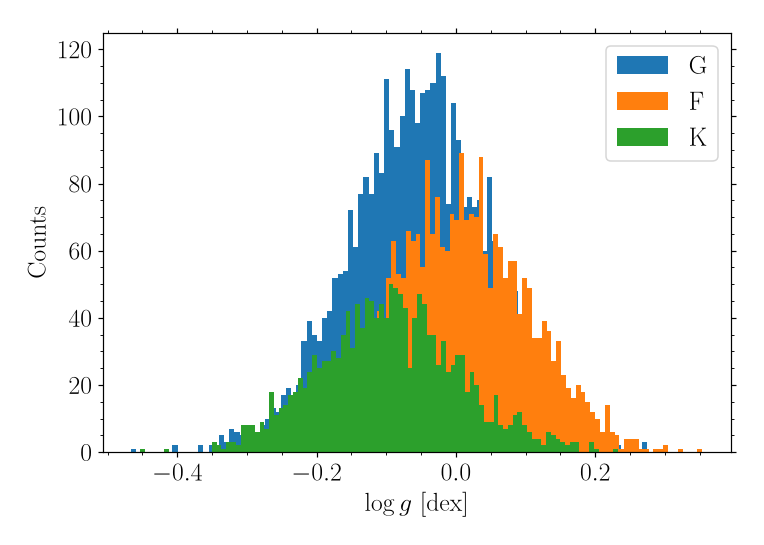

In [22]:
# Metallicity in solar neighbourhood
# F and G dwarfs (Bensby+2014)
# https://ui.adsabs.harvard.edu/abs/2014A%26A...562A..71B/abstract
dF['Z'] = rng.normal(0, 0.1, dF.shape[0]) 
dG['Z'] = rng.normal(-0.05, 0.1, dG.shape[0]) 
# K dwarfs [-0.4, 0.2] (Kotoneva+2002)
# https://academic.oup.com/mnras/article/336/3/879/973554
dK['Z'] = rng.normal(-0.1, 0.1, dK.shape[0]) 
# Combine back into a single catalogue
dt = pd.concat([dF, dG, dK])
# Show distributions
plt.figure(figsize=(7,5))
plt.hist(dG.Z, bins=100, label='G')
plt.hist(dF.Z, bins=100, label='F')
plt.hist(dK.Z, bins=100, label='K')
plt.xlabel(r'$\log g$ [dex]')
plt.ylabel('Counts')
plt.legend()
plt.tight_layout()

<IPython.core.display.Javascript object>


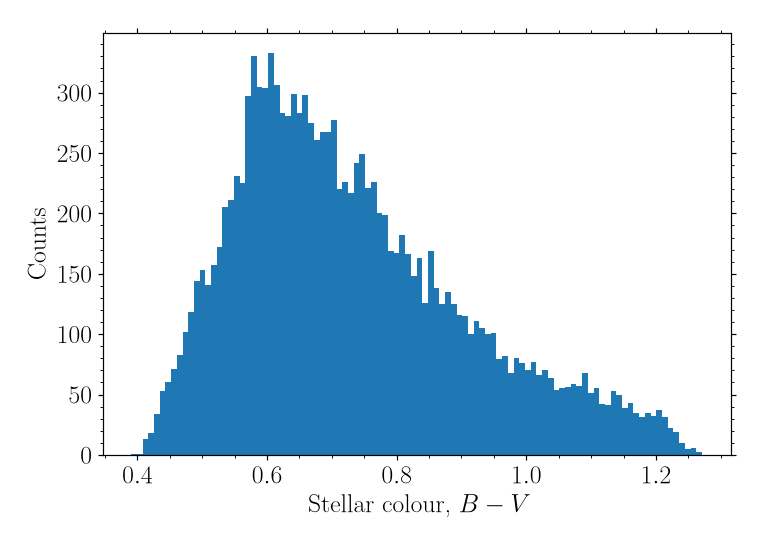

0

In [9]:
# Load PyAstronomy colour transformation using Teff:
# This uses the relation for main-sequence FGK stars (Ballesteros+2012)
# https://pyastronomy.readthedocs.io/en/latest/pyaslDoc/aslDoc/aslExt_1Doc/ramirez2005.html
r = pyasl.Ramirez2005()
dt['BV'] = [r.teffToColor_nop('B-V', dt.Teff.iloc[i], dt.Z.iloc[i], noRaise=True) for i in range(dt.shape[0])]
# Show distributions
plt.figure(figsize=(7,5))
plt.hist(dt.BV, bins=100)
plt.xlabel(r'Stellar colour, $B-V$')
plt.ylabel('Counts')
plt.tight_layout()
# If any warnings, check how many stars that are within the M dwarf regime
dt[dt.Teff < 3316.8].shape[0]

<IPython.core.display.Javascript object>


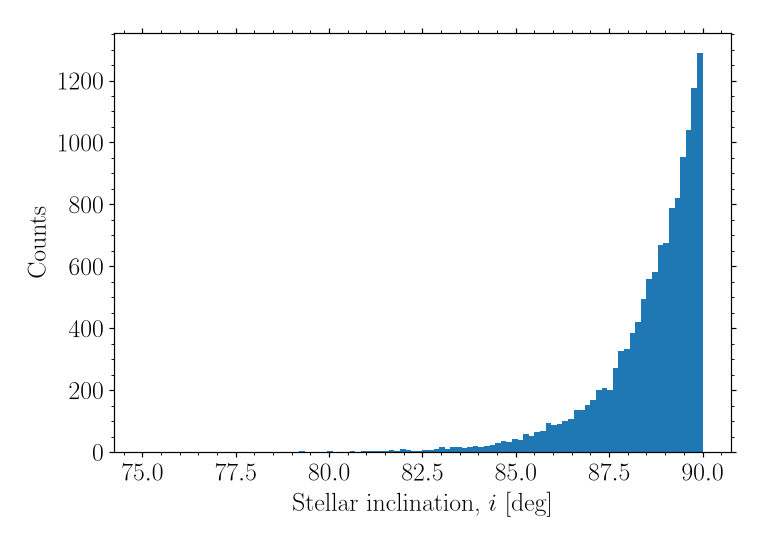

In [10]:
# Draw stellar inclination from exponential distribution
x = rng.exponential(scale=1, size=dt.shape[0])
dt['i'] = 90 - 15 * x/x.max()
# Show distributions
plt.figure(figsize=(7,5))
plt.hist(dt.i, bins=100)
plt.xlabel(r'Stellar inclination, $i$ [deg]')
plt.ylabel('Counts')
plt.tight_layout()

## Plot targets in LOPS2 footprint

<IPython.core.display.Javascript object>


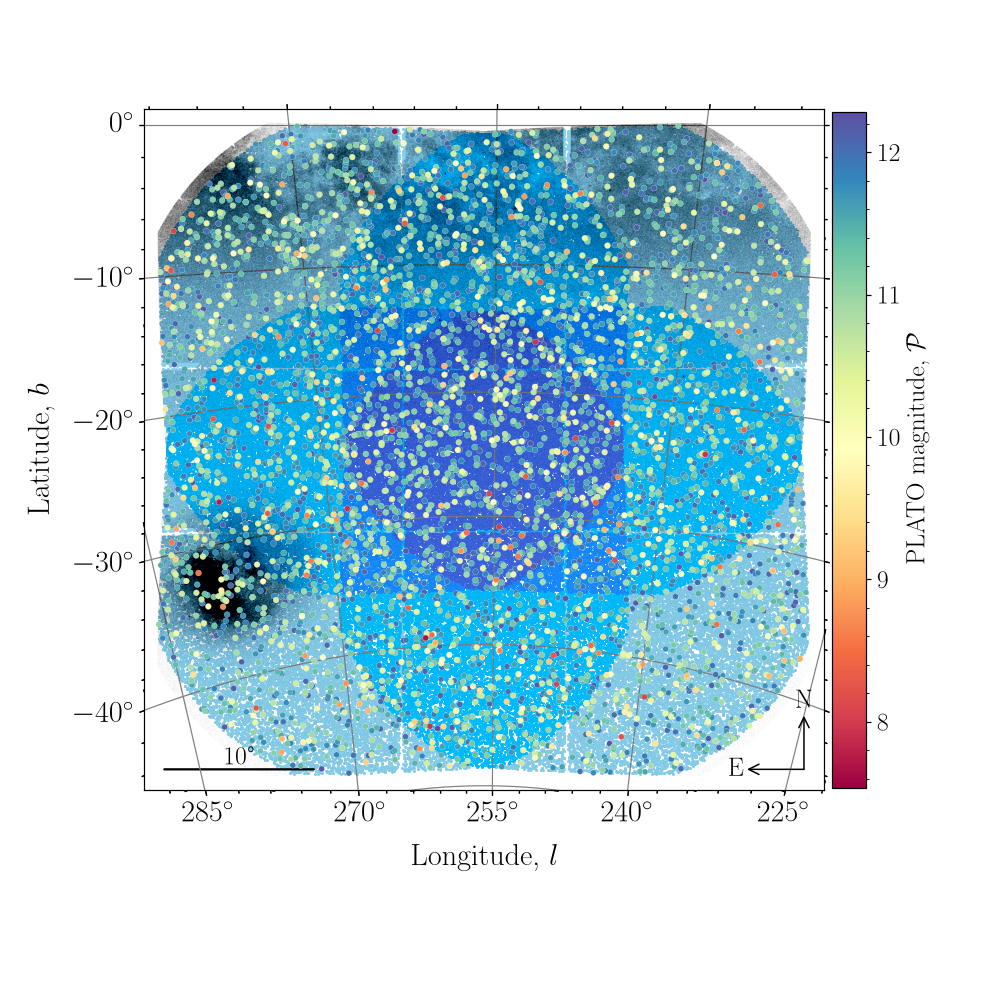

In [17]:
# Plot catalogue within LOPS2 foorptint
dx = dK
fig, ax = pt.plotPlatoFOV(
    'LOPS2', system='galactic', ncamStars=True, showGalactic=True,
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, 
    cbarExtend=None, s=50, lw=0.15, ec='w', fovSize=27.5,
    clabel=r'PLATO magnitude, $\mathcal{P}$', cmap='Spectral', figsize=(9,9)
)
# fig.savefig(fdir / 'starcat_footprint.png', bbox_inches='tight', dpi=200)

## Plot parameter space

In [93]:
dt.columns

Index(['ID', 'PIC', 'gaiaDR3', 'l', 'b', 'ra', 'dec', 'pmra', 'pmdec', 'plx',
       'Pmag', 'PBmag', 'PRmag', 'Vmag', 'M', 'M_err', 'R', 'R_err', 'Teff',
       'Teff_err', 'logg', 'ncams', 'case', 'source', 'tPIC', 'fgPIC', 'cPIC',
       'scvPIC', 'ncon', 'Z', 'BV'],
      dtype='str')

### Spectroscopic HR diagram + Mag vs M

<IPython.core.display.Javascript object>


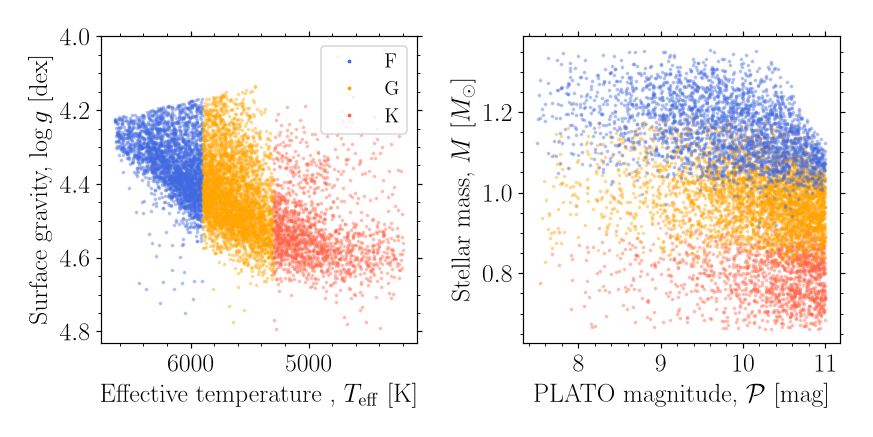

In [121]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
aa, ms = 0.3, 3
cc = ['tomato', 'orange', 'royalblue']

# Plot Teff vs. logg
ax[0].plot(dF.Teff, dF.logg, '.', ms=ms, alpha=aa, label='F', c=cc[2])
ax[0].plot(dG.Teff, dG.logg, '.', ms=ms, alpha=aa, label='G', c=cc[1])
ax[0].plot(dK.Teff, dK.logg, '.', ms=ms, alpha=aa, label='K', c=cc[0])
ax[0].set_xlabel(r'Effective temperature , $T_{\rm eff}$ [K]')
ax[0].set_ylabel(r'Surface gravity, $\log g$ [dex]')
ax[0].xaxis.set_inverted(True)
ax[0].yaxis.set_inverted(True)
leg = ax[0].legend(loc='upper right', fontsize=13)
pt.makeLegendMarkersOpaque(leg)
        
# Plot Pmag vs. M
ax[1].plot(dK.Pmag, dK.M, '.', ms=ms, alpha=aa, c=cc[0])
ax[1].plot(dG.Pmag, dG.M, '.', ms=ms, alpha=aa, c=cc[1])
ax[1].plot(dF.Pmag, dF.M, '.', ms=ms, alpha=aa, c=cc[2])
ax[1].set_xlabel(r'PLATO magnitude, $\mathcal{P}$ [mag]')
ax[1].set_ylabel(r'Stellar mass, $M$ [$M_{\odot}$]')

plt.tight_layout()
fig.savefig(fdir / 'starcat_stellar_parameters_spec.png', bbox_inches='tight', dpi=200)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
aa, ms = 0.3, 3
cc = ['tomato', 'orange', 'royalblue']

# Plot Teff vs. logg
ax[0].plot(dF.R, dF.logg, '.', ms=ms, alpha=aa, label='F', c=cc[2])
ax[0].plot(dG.R, dG.M, '.', ms=ms, alpha=aa, label='G', c=cc[1])
ax[0].plot(dK.R, dK.M, '.', ms=ms, alpha=aa, label='K', c=cc[0])
ax[0].set_xlabel(r'Effective temperature , $T_{\rm eff}$ [K]')
ax[0].set_ylabel(r'Surface gravity, $\log g$ [dex]')
ax[0].xaxis.set_inverted(True)
ax[0].yaxis.set_inverted(True)
leg = ax[0].legend(loc='upper right', fontsize=13)
pt.makeLegendMarkersOpaque(leg)
        
# Plot Pmag vs. M
ax[1].plot(dK.Pmag, dK.M, '.', ms=ms, alpha=aa, c=cc[0])
ax[1].plot(dG.Pmag, dG.M, '.', ms=ms, alpha=aa, c=cc[1])
ax[1].plot(dF.Pmag, dF.M, '.', ms=ms, alpha=aa, c=cc[2])
ax[1].set_xlabel(r'PLATO magnitude, $\mathcal{P}$ [mag]')
ax[1].set_ylabel(r'Stellar mass, $M$ [$M_{\odot}$]')

plt.tight_layout()

### PIC stellar parameters

In [191]:
df = dt.copy()
P_min, P_max = df.Pmag.min(), df.Pmag.max()
M_min, M_max = df.M.min(), df.M.max()
R_min, R_max = df.R.min(), df.R.max()
Teff_min, Teff_max = df.Teff.min(), df.Teff.max()
logg_min, logg_max = df.logg.min(), df.logg.max()
Z_min, Z_max = df.Z.min(), df.Z.max()
# Seperate stars
df06 = df[df.ncams ==  6]
df12 = df[df.ncams == 12]
df18 = df[df.ncams == 18]
df24 = df[df.ncams == 24]
# Settings
lw = 2
N = 60
c = ['lightseagreen', 'royalblue', 'orange', 'deeppink']
params = ['Pmag', 'BV', 'M', 'R', 'Teff', 'logg', 'Z']
lab = [
    r'PLATO magnitude, $\mathcal{P}$',
    r'Johnsin-Cousin colour, $B-V$',
    r'Mass, $M$ [$M_{\odot}$]',
    r'Radius, $R$ [$R_{\odot}$]',
    r'Effective temperature, $T_{\rm eff}$ [K]',
    r'Surface gravity, log $g$',
    r'Metallicity, [Fe/H]',
]
n = len(lab)

<IPython.core.display.Javascript object>


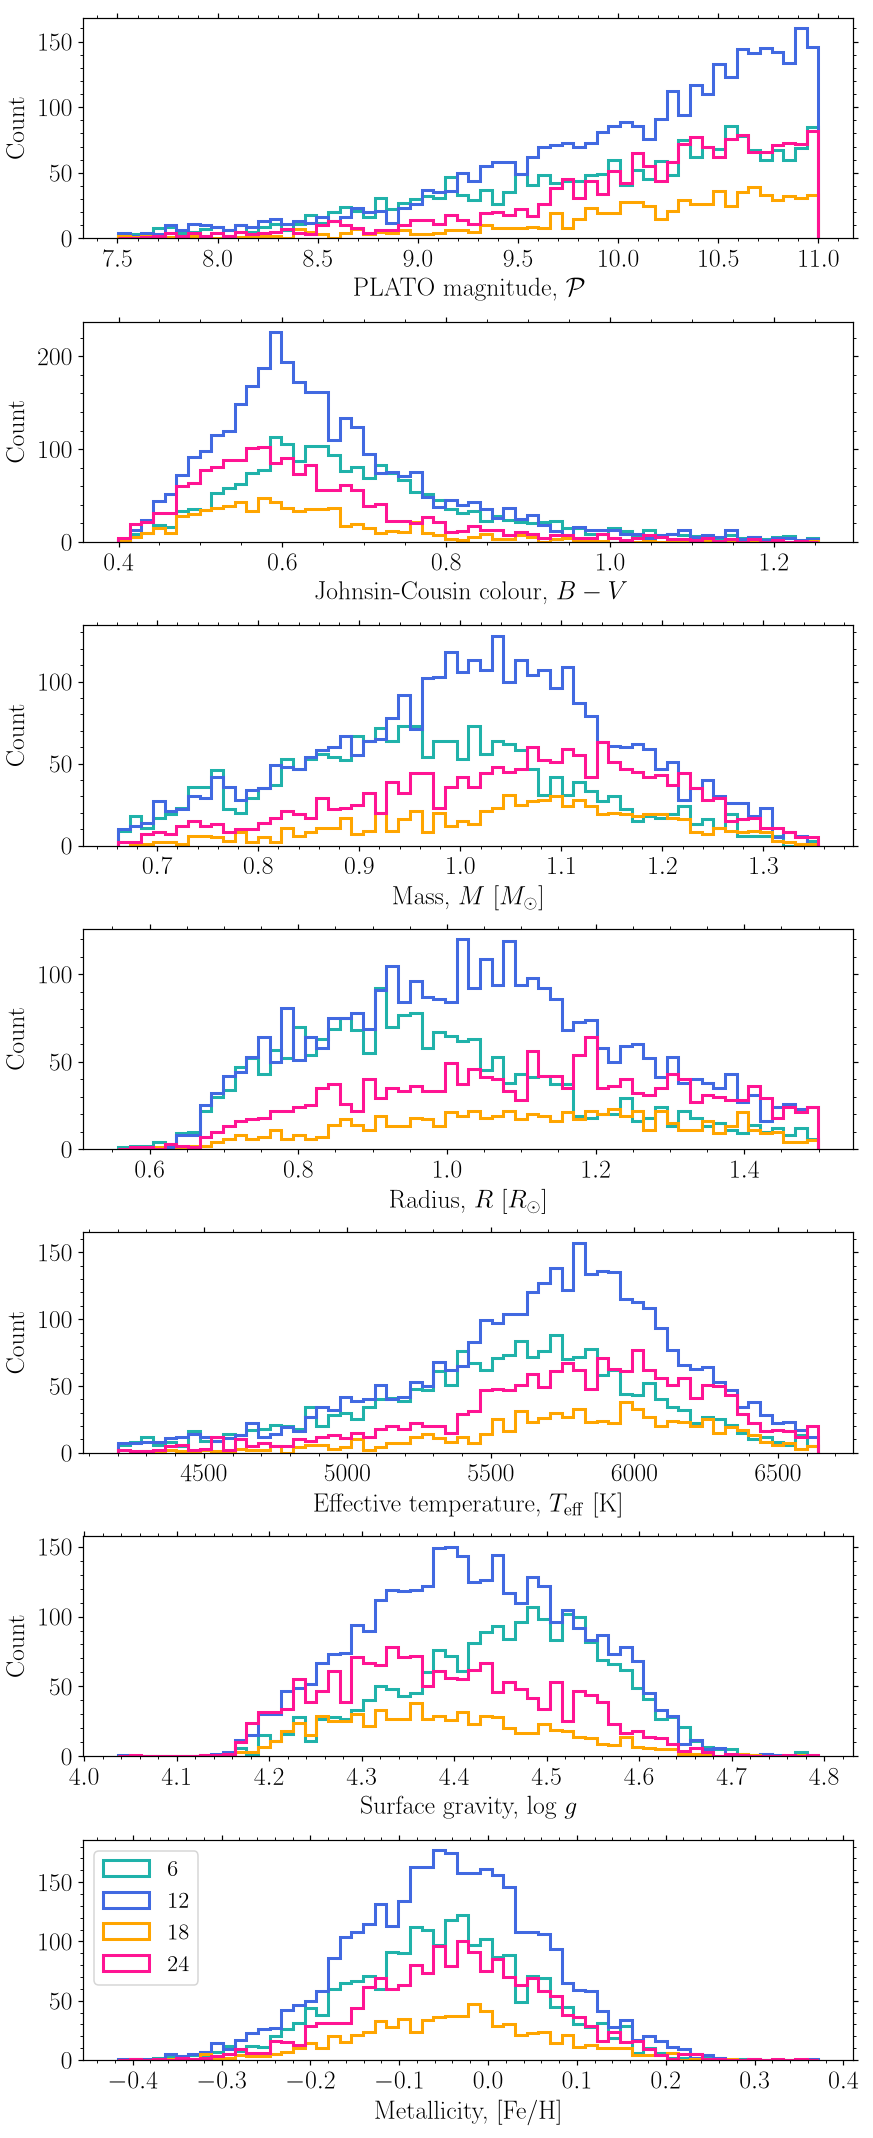

In [198]:
fig, ax = plt.subplots(n, 1, figsize=(8, 2.8*n))
# Plot each parameter
for i,p in zip(range(n), params):
    if i != (n-1): leg = [None, None, None, None]
    else: leg = ['6', '12', '18', '24']
    ax[i].hist(df06[p], bins=N, range=(df[p].min(), df[p].max()), histtype='step', ec=c[0], lw=lw, label=leg[0])
    ax[i].hist(df12[p], bins=N, range=(df[p].min(), df[p].max()), histtype='step', ec=c[1], lw=lw, label=leg[1])
    ax[i].hist(df18[p], bins=N, range=(df[p].min(), df[p].max()), histtype='step', ec=c[2], lw=lw, label=leg[2])
    ax[i].hist(df24[p], bins=N, range=(df[p].min(), df[p].max()), histtype='step', ec=c[3], lw=lw, label=leg[3])
    ax[i].set_xlabel(lab[i])
    # Settings
    for i in range(6):
        ax[i].set_ylabel('Count')
        ax[i].get_yaxis().set_label_coords(-0.07, 0.5)
plt.tight_layout(pad=0.5)
ax[n-1].legend(loc='upper left')
fig.savefig(fdir / 'starcat_stellar_parameters_hist.png', bbox_inches='tight', dpi=200)

In [148]:
# Show min max parameter space
params = ['Pmag', 'BV', 'M', 'R', 'Teff', 'logg', 'Z']
for i in params:
    print(f'{df[i].min():.2f}, {df[i].max():.2f}')

7.50, 11.00
0.40, 1.28
0.66, 1.35
0.56, 1.50
4201.24, 6640.83
4.04, 4.79
-0.45, 0.35


<IPython.core.display.Javascript object>


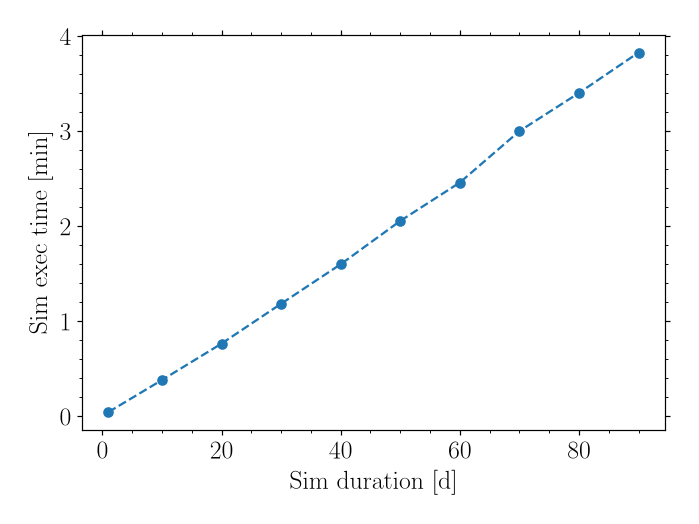

In [30]:
# pt.plotHistogramSED(dt, title=False, figsize=(8,15))
plt.figure()
plt.plot([1, 10, 20, 30, 40, 50, 60, 70, 80, 90],
        np.array([
            2.767026,
            23.019028, 
            45.989205, 
            60*1+11.143191,
            60*1+36.052075,
            60*2+03.386296,
            60*2+27.586887,
            60*3+00.027331,
            60*3+24.115025,
            60*3+49.616240
        ])/60, 
         'o--')
plt.xlabel('Sim duration [d]')
plt.ylabel('Sim exec time [min]')
plt.tight_layout()